In [ ]:
!unzip '/content/project-22-at-2026-08-21-14-14-4218fe47.zip' -d '/content/dataset'

Archive:  /content/project-22-at-2026-08-21-14-14-4218fe47.zip
   creating: /content/dataset/images/
   creating: /content/dataset/labels/
  inflating: /content/dataset/classes.txt  
  inflating: /content/dataset/notes.json  
  inflating: /content/dataset/images/006cb1e9-photo_7_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/009c13ff-photo_14_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/030620d7-photo_10_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/0f6156fc-photo_6_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/1f120590-photo_19_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/36ae1548-photo_20_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/3c6aecd8-photo_5_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/4bea5f20-photo_11_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/527d02b7-photo_9_2026-08-08_12-42-34.jpg  
  inflating: /content/dataset/images/73aab22b-pho

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 5.8 MB/s eta 0:00:00


In [ ]:
import convert2
#если нужно запустить несколько раз - convert2.split_yolo_dataset('/content/dataset')

ПРОВЕРКА YOLO DATASET
Папка изображений: dataset/images
Папка разметки:     dataset/labels

Найдено изображений: 20
Расширения изображений:
  .jpg: 20

Найдено TXT-файлов: 20
Расширения разметки:
  .txt: 20

ПРОВЕРКА СООТВЕТСТВИЯ
Всего изображений:          20
Изображений с TXT:          20
Изображений без TXT:        0

РАЗДЕЛЕНИЕ DATASET
Всего пар:     20
Train:         16
Validation:    4


РЕЗУЛЬТАТ
Train успешно:      16
Train ошибок:       0
Val успешно:        4
Val ошибок:         0
Всего перемещено:   20

Dataset успешно разделён!


In [ ]:
from ultralytics import YOLO

In [ ]:
model = YOLO('yolov8m.pt')

In [ ]:
train = model.train(data='/content/dataset/data.yaml',
                    epochs=100, imgsz=640, batch=8)

Ultralytics 8.4.125 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=Non

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

In [ ]:
model = YOLO('/content/runs/detect/train/weights/best.pt')


0: 480x640 1 glasses, 27.5ms
Speed: 3.8ms preprocess, 27.5ms inference, 10.2ms postprocess per image at shape (1, 3, 480, 640)


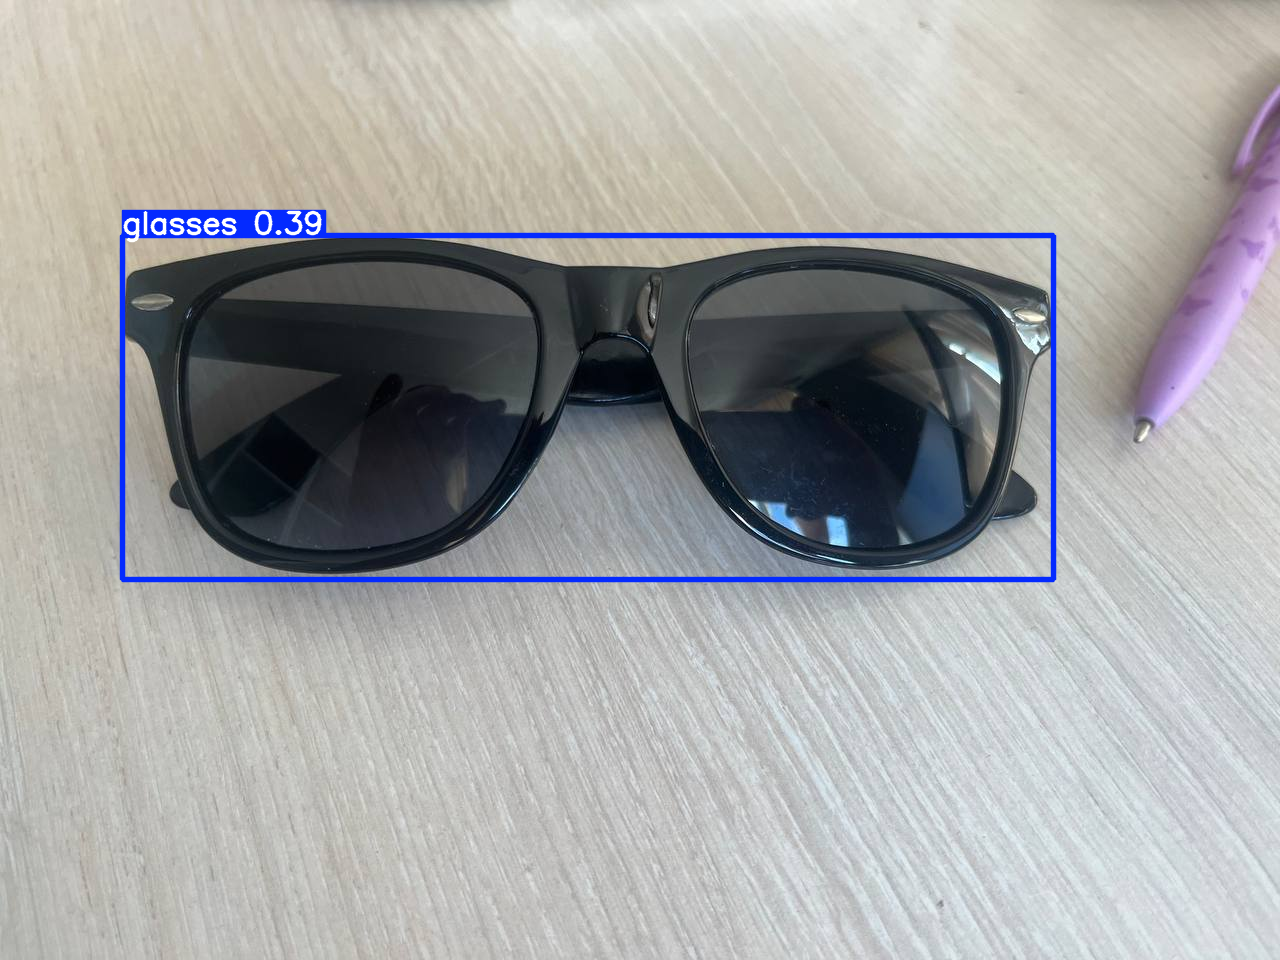

In [ ]:
img = cv2.imread('/content/new.jpg')
results = model(img)
for result in results:
  final_frame = result.plot()
  cv2_imshow(final_frame)